In [8]:
import pandas as pd

file_path = r"D:\MASTERS\FOML\assignment\202618026_AumTailor_DS605\202618026_Lab_08\data_banknote_authentication.txt"

df = pd.read_csv(file_path, header=None)

df.head()

,0,1,2,3,4
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [9]:
df.columns = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

print(df.head())
print(df.shape)
print(df.info())
print(df["class"].value_counts())

   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0
(1372, 5)
<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB
None
class
0    762
1    610
Name: count, dtype: int64


In [10]:
import numpy as np

def gini_impurity(y):
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1 - np.sum(probabilities ** 2)


def entropy(y):
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return -np.sum(probabilities * np.log2(probabilities))

In [11]:
def split_data(X, y, feature_index, threshold):
    left_mask = X[:, feature_index] <= threshold
    right_mask = ~left_mask

    X_left = X[left_mask]
    y_left = y[left_mask]

    X_right = X[right_mask]
    y_right = y[right_mask]

    return X_left, y_left, X_right, y_right

In [12]:
def weighted_impurity(y_left, y_right, criterion="gini"):
    n = len(y_left) + len(y_right)

    if len(y_left) == 0 or len(y_right) == 0:
        return float("inf")

    impurity_func = gini_impurity if criterion == "gini" else entropy

    left_impurity = impurity_func(y_left)
    right_impurity = impurity_func(y_right)

    weighted = (
        (len(y_left) / n) * left_impurity
        + (len(y_right) / n) * right_impurity
    )

    return weighted

In [13]:
X = df[["variance", "skewness"]].to_numpy()
y = df["class"].to_numpy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1372, 2)
y shape: (1372,)


In [14]:
X_left, y_left, X_right, y_right = split_data(
    X, y, feature_index=0, threshold=0.5
)

print("Left samples:", len(y_left))
print("Right samples:", len(y_right))

print("Weighted Gini:", weighted_impurity(y_left, y_right))

Left samples: 687
Right samples: 685
Weighted Gini: 0.2580495314271986


## Find the best split

In [15]:
def best_split(X, y, criterion="gini"):
    best_feature = None
    best_threshold = None
    best_impurity = float("inf")

    n_features = X.shape[1]

    impurity_func = gini_impurity if criterion == "gini" else entropy

    for feature_index in range(n_features):

        values = np.unique(X[:, feature_index])

        # Candidate thresholds between consecutive values
        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:

            left_mask = X[:, feature_index] <= threshold
            right_mask = ~left_mask

            y_left = y[left_mask]
            y_right = y[right_mask]

            if len(y_left) == 0 or len(y_right) == 0:
                continue

            n = len(y)

            weighted = (
                (len(y_left) / n) * impurity_func(y_left)
                + (len(y_right) / n) * impurity_func(y_right)
            )

            if weighted < best_impurity:
                best_impurity = weighted
                best_feature = feature_index
                best_threshold = threshold

    return best_feature, best_threshold, best_impurity

In [16]:
feature, threshold, impurity = best_split(X, y, criterion="gini")

feature_names = ["variance", "skewness"]

print("Best feature:", feature_names[feature])
print("Best threshold:", threshold)
print("Weighted Gini impurity:", impurity)

Best feature: variance
Best threshold: 0.320165
Weighted Gini impurity: 0.24679933491786998


In [17]:
def build_tree(X, y, max_depth=5, min_samples_split=2,
               criterion="gini", depth=0):

    # Stop if the node is pure
    if len(np.unique(y)) == 1:
        return {"leaf": True, "class": y[0]}

    # Stop if maximum depth is reached
    if depth >= max_depth:
        return {
            "leaf": True,
            "class": np.bincount(y).argmax()
        }

    # Stop if there are too few samples
    if len(y) < min_samples_split:
        return {
            "leaf": True,
            "class": np.bincount(y).argmax()
        }

    feature, threshold, impurity = best_split(
        X, y, criterion
    )

    # Stop if no valid split exists
    if feature is None:
        return {
            "leaf": True,
            "class": np.bincount(y).argmax()
        }

    X_left, y_left, X_right, y_right = split_data(
        X, y, feature, threshold
    )

    # Recursively build child nodes
    left_child = build_tree(
        X_left, y_left, max_depth, min_samples_split,
        criterion, depth + 1
    )

    right_child = build_tree(
        X_right, y_right, max_depth, min_samples_split,
        criterion, depth + 1
    )

    return {
        "leaf": False,
        "feature": feature,
        "threshold": threshold,
        "left": left_child,
        "right": right_child
    }

In [18]:
tree = build_tree(
    X, y,
    max_depth=3,
    min_samples_split=2,
    criterion="gini"
)

print(tree)

{'leaf': False, 'feature': 0, 'threshold': np.float64(0.320165), 'left': {'leaf': False, 'feature': 1, 'threshold': np.float64(7.5653), 'left': {'leaf': False, 'feature': 0, 'threshold': np.float64(-0.4031), 'left': {'leaf': True, 'class': np.int64(1)}, 'right': {'leaf': True, 'class': np.int64(1)}}, 'right': {'leaf': False, 'feature': 0, 'threshold': np.float64(-4.726), 'left': {'leaf': True, 'class': np.int64(1)}, 'right': {'leaf': True, 'class': np.int64(0)}}}, 'right': {'leaf': False, 'feature': 0, 'threshold': np.float64(1.7438500000000001), 'left': {'leaf': False, 'feature': 1, 'threshold': np.float64(5.27355), 'left': {'leaf': True, 'class': np.int64(0)}, 'right': {'leaf': True, 'class': np.int64(0)}}, 'right': {'leaf': False, 'feature': 0, 'threshold': np.float64(2.3921), 'left': {'leaf': True, 'class': np.int64(0)}, 'right': {'leaf': True, 'class': np.int64(0)}}}}


In [19]:
def predict_one(node, x):
    # If we reach a leaf, return its predicted class
    if node["leaf"]:
        return node["class"]

    feature = node["feature"]
    threshold = node["threshold"]

    if x[feature] <= threshold:
        return predict_one(node["left"], x)
    else:
        return predict_one(node["right"], x)


def predict_tree(tree, X):
    return np.array([
        predict_one(tree, x) for x in X
    ])

In [20]:
y_pred = predict_tree(tree, X)

print("First 10 actual labels:", y[:10])
print("First 10 predictions:", y_pred[:10])

accuracy = np.mean(y_pred == y)

print("Training accuracy:", accuracy)

First 10 actual labels: [0 0 0 0 0 0 0 0 0 0]
First 10 predictions: [0 0 0 0 0 0 0 0 0 0]
Training accuracy: 0.9154518950437318


In [21]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion matrix:")
print(confusion_matrix(y, y_pred))

print("\nClassification report:")
print(classification_report(y, y_pred))

Confusion matrix:
[[723  39]
 [ 77 533]]

Classification report:
              precision    recall  f1-score   support

           0       0.90      0.95      0.93       762
           1       0.93      0.87      0.90       610

    accuracy                           0.92      1372
   macro avg       0.92      0.91      0.91      1372
weighted avg       0.92      0.92      0.92      1372



In [22]:
def print_tree(node, feature_names, depth=0):
    indent = "  " * depth

    if node["leaf"]:
        print(f"{indent}Predict class: {node['class']}")
        return

    feature = feature_names[node["feature"]]
    threshold = node["threshold"]

    print(f"{indent}if {feature} <= {threshold:.4f}:")
    print_tree(node["left"], feature_names, depth + 1)

    print(f"{indent}else:  # {feature} > {threshold:.4f}")
    print_tree(node["right"], feature_names, depth + 1)


feature_names = ["variance", "skewness"]

print_tree(tree, feature_names)

if variance <= 0.3202:
  if skewness <= 7.5653:
    if variance <= -0.4031:
      Predict class: 1
    else:  # variance > -0.4031
      Predict class: 1
  else:  # skewness > 7.5653
    if variance <= -4.7260:
      Predict class: 1
    else:  # variance > -4.7260
      Predict class: 0
else:  # variance > 0.3202
  if variance <= 1.7439:
    if skewness <= 5.2736:
      Predict class: 0
    else:  # skewness > 5.2736
      Predict class: 0
  else:  # variance > 1.7439
    if variance <= 2.3921:
      Predict class: 0
    else:  # variance > 2.3921
      Predict class: 0


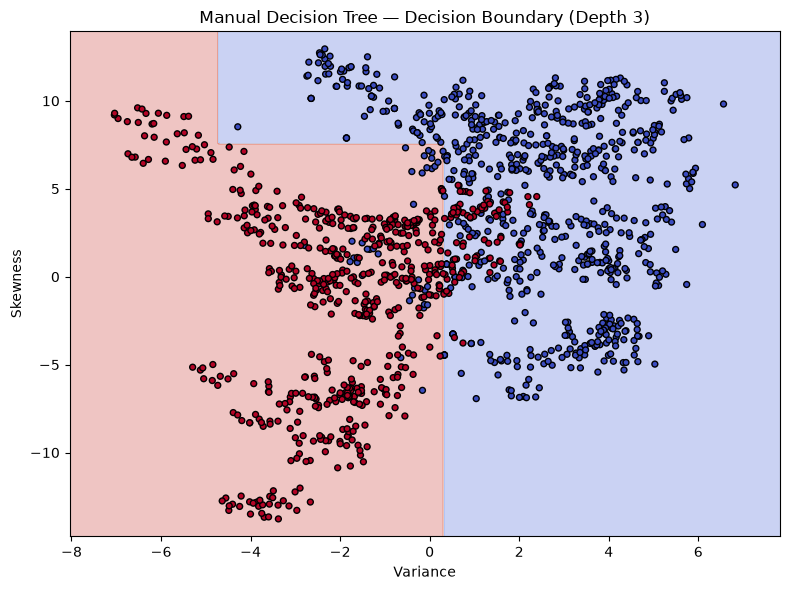

In [23]:
import matplotlib.pyplot as plt

def plot_decision_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm",
                edgecolors="k", s=18)

    plt.xlabel("Variance")
    plt.ylabel("Skewness")
    plt.title(title)
    plt.tight_layout()
    plt.show()


plot_decision_boundary(
    lambda points: predict_tree(tree, points),
    X, y,
    "Manual Decision Tree — Decision Boundary (Depth 3)"
)

In [24]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

sk_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

sk_tree.fit(X, y)

sk_pred = sk_tree.predict(X)

print("Scikit-learn training accuracy:",
      np.mean(sk_pred == y))

Scikit-learn training accuracy: 0.9154518950437318


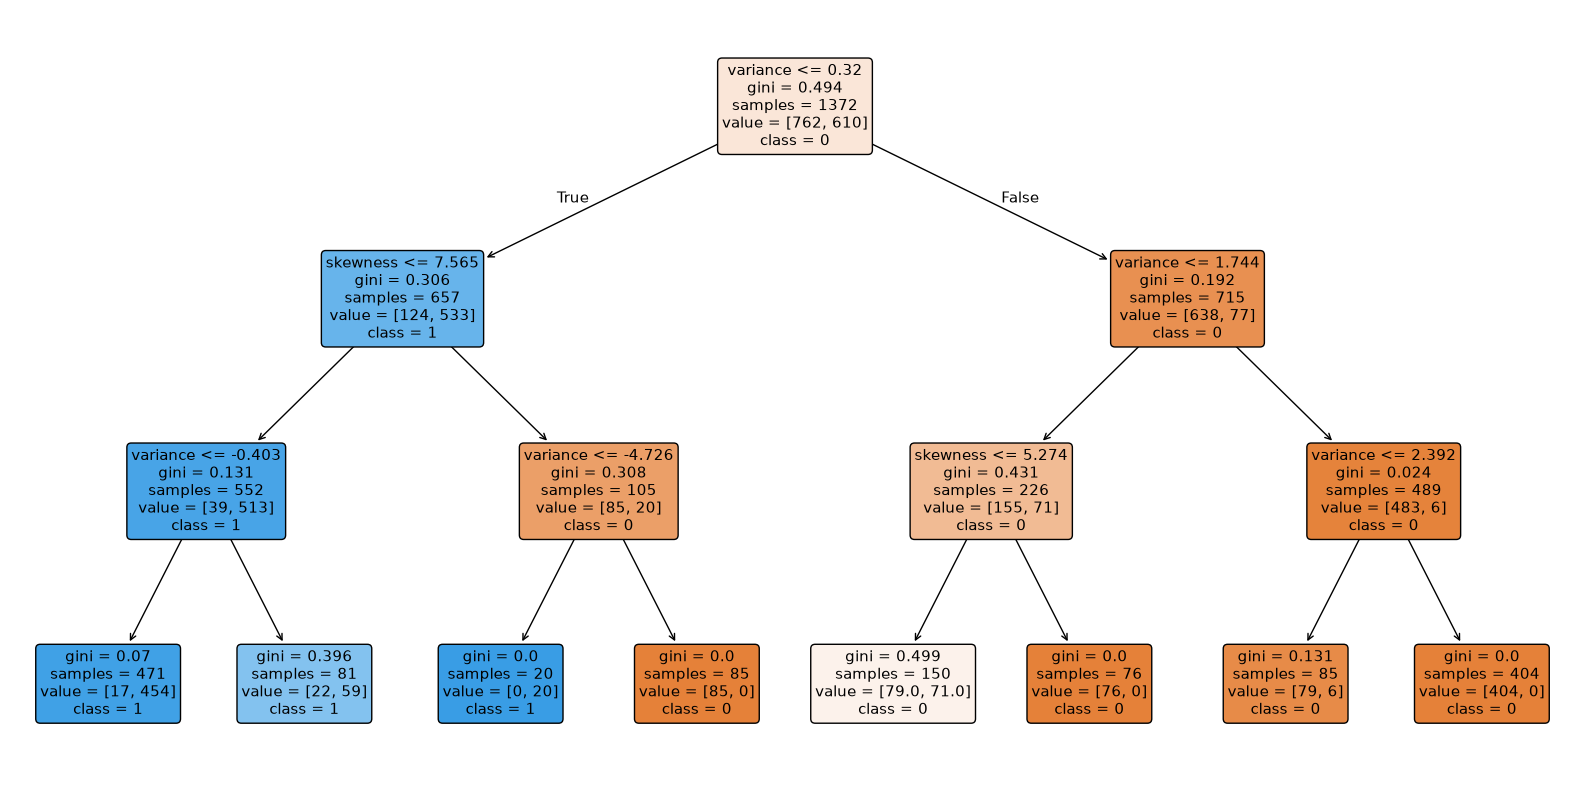

In [25]:
plt.figure(figsize=(16, 8))

plot_tree(
    sk_tree,
    feature_names=["variance", "skewness"],
    class_names=["0", "1"],
    filled=True,
    rounded=True
)

plt.tight_layout()
plt.show()

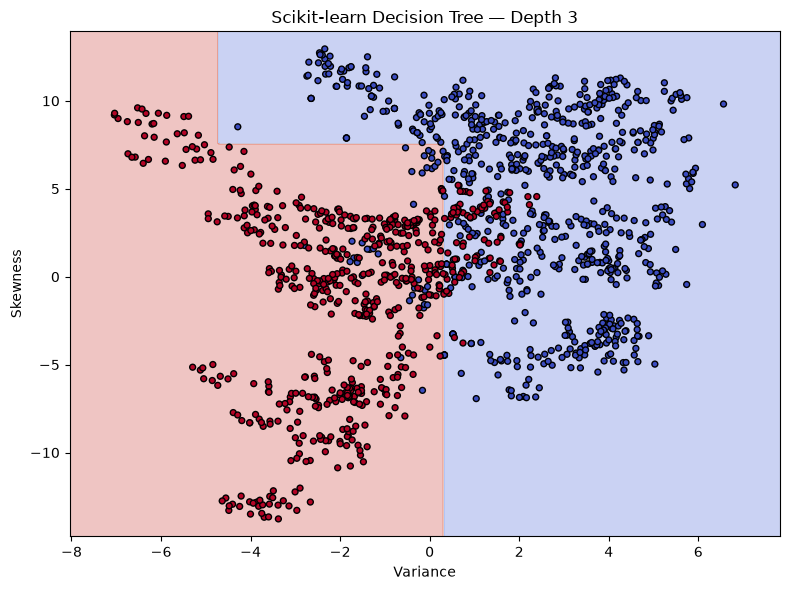

In [26]:
plot_decision_boundary(
    sk_tree.predict,
    X, y,
    "Scikit-learn Decision Tree — Depth 3"
)

In [27]:
criteria = ["gini", "entropy"]
depths = [1, 2, 3, 5, 10]

results = []

for criterion in criteria:
    for depth in depths:
        model = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            random_state=42
        )

        model.fit(X, y)
        predictions = model.predict(X)

        results.append({
            "Criterion": criterion,
            "Max Depth": depth,
            "Training Accuracy": np.mean(predictions == y),
            "Number of Leaves": model.get_n_leaves()
        })

results_df = pd.DataFrame(results)
print(results_df)

  Criterion  Max Depth  Training Accuracy  Number of Leaves
0      gini          1           0.853499                 2
1      gini          2           0.900875                 4
2      gini          3           0.915452                 8
3      gini          5           0.943878                18
4      gini         10           0.992711                72
5   entropy          1           0.853499                 2
6   entropy          2           0.895773                 4
7   entropy          3           0.923469                 8
8   entropy          5           0.946064                20
9   entropy         10           0.989796                69


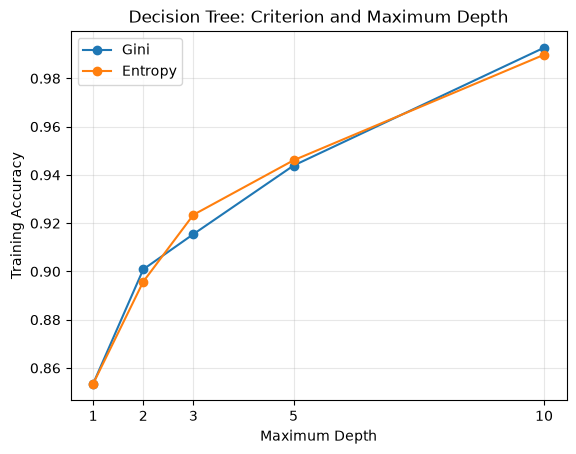

In [28]:
import matplotlib.pyplot as plt

for criterion in ["gini", "entropy"]:
    subset = results_df[results_df["Criterion"] == criterion]

    plt.plot(
        subset["Max Depth"],
        subset["Training Accuracy"],
        marker="o",
        label=criterion.capitalize()
    )

plt.xlabel("Maximum Depth")
plt.ylabel("Training Accuracy")
plt.title("Decision Tree: Criterion and Maximum Depth")
plt.xticks([1, 2, 3, 5, 10])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1097
Testing samples: 275


In [30]:
manual_tree = build_tree(
    X_train, y_train,
    max_depth=3,
    min_samples_split=2,
    criterion="gini"
)

manual_train_pred = predict_tree(manual_tree, X_train)
manual_test_pred = predict_tree(manual_tree, X_test)

print("Manual tree train accuracy:",
      accuracy_score(y_train, manual_train_pred))

print("Manual tree test accuracy:",
      accuracy_score(y_test, manual_test_pred))

Manual tree train accuracy: 0.9288969917958068
Manual tree test accuracy: 0.9090909090909091


In [31]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

sk_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

sk_tree.fit(X_train, y_train)

sk_train_pred = sk_tree.predict(X_train)
sk_test_pred = sk_tree.predict(X_test)

print("Sklearn train accuracy:",
      accuracy_score(y_train, sk_train_pred))

print("Sklearn test accuracy:",
      accuracy_score(y_test, sk_test_pred))

Sklearn train accuracy: 0.9288969917958068
Sklearn test accuracy: 0.9090909090909091


In [32]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Manual Decision Tree",
        "Accuracy": accuracy_score(y_test, manual_test_pred),
        "Precision": precision_score(y_test, manual_test_pred),
        "Recall": recall_score(y_test, manual_test_pred),
        "F1-score": f1_score(y_test, manual_test_pred)
    },
    {
        "Model": "Sklearn Decision Tree",
        "Accuracy": accuracy_score(y_test, sk_test_pred),
        "Precision": precision_score(y_test, sk_test_pred),
        "Recall": recall_score(y_test, sk_test_pred),
        "F1-score": f1_score(y_test, sk_test_pred)
    }
])

print(comparison.round(4))

                   Model  Accuracy  Precision  Recall  F1-score
0   Manual Decision Tree    0.9091      0.876  0.9262    0.9004
1  Sklearn Decision Tree    0.9091      0.876  0.9262    0.9004


In [33]:
import time
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

# Manual tree: training time
start = time.perf_counter()

manual_tree = build_tree(
    X_train, y_train,
    max_depth=3,
    min_samples_split=2,
    criterion="gini"
)

manual_train_time = time.perf_counter() - start

# Manual tree: prediction time
start = time.perf_counter()
manual_test_pred = predict_tree(manual_tree, X_test)
manual_predict_time = time.perf_counter() - start


# Scikit-learn tree: training time
sk_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

start = time.perf_counter()
sk_tree.fit(X_train, y_train)
sk_train_time = time.perf_counter() - start

# Scikit-learn tree: prediction time
start = time.perf_counter()
sk_test_pred = sk_tree.predict(X_test)
sk_predict_time = time.perf_counter() - start


timing_results = pd.DataFrame({
    "Model": ["Manual Tree", "Scikit-learn Tree"],
    "Training Time (s)": [manual_train_time, sk_train_time],
    "Prediction Time (s)": [manual_predict_time, sk_predict_time]
})

print(timing_results)

               Model  Training Time (s)  Prediction Time (s)
0        Manual Tree           0.234548             0.000270
1  Scikit-learn Tree           0.001443             0.000201


## Part B — Linear SVM from scratch

In [34]:
import numpy as np

# Calculate statistics using training data only
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)

# Standardize training and test data
X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

print("Training means:", X_train_scaled.mean(axis=0))
print("Training standard deviations:", X_train_scaled.std(axis=0))

Training means: [-8.72390380e-17 -3.24666861e-16]
Training standard deviations: [1. 1.]


In [35]:
y_train_svm = np.where(y_train == 1, 1, -1)
y_test_svm = np.where(y_test == 1, 1, -1)

print("Original labels:", np.unique(y_train))
print("SVM labels:", np.unique(y_train_svm))

Original labels: [0 1]
SVM labels: [-1  1]


In [36]:
def svm_objective(X, y, w, b, C):
    scores = X @ w + b
    margins = y * scores

    hinge_losses = np.maximum(0, 1 - margins)

    regularization = 0.5 * np.dot(w, w)
    loss = regularization + C * np.sum(hinge_losses)

    return loss

In [37]:
def svm_subgradient(X, y, w, b, C):
    n = len(y)

    margins = y * (X @ w + b)
    violating = margins < 1

    dw = w - C * np.sum(
        (y[violating, None] * X[violating]),
        axis=0
    )

    db = -C * np.sum(y[violating])

    return dw, db

In [38]:
w = np.zeros(X_train_scaled.shape[1])
b = 0.0
C = 1.0

print("Initial objective:",
      svm_objective(X_train_scaled, y_train_svm, w, b, C))

dw, db = svm_subgradient(
    X_train_scaled, y_train_svm, w, b, C
)

print("Weight subgradient:", dw)
print("Bias subgradient:", db)

Initial objective: 1097.0
Weight subgradient: [784.35036806 483.1950927 ]
Bias subgradient: 121.0


In [39]:
def train_svm(X, y, C=1.0, learning_rate=0.0001, n_iterations=2000):
    w = np.zeros(X.shape[1])
    b = 0.0
    losses = []

    for iteration in range(n_iterations):
        dw, db = svm_subgradient(X, y, w, b, C)

        w = w - learning_rate * dw
        b = b - learning_rate * db

        loss = svm_objective(X, y, w, b, C)
        losses.append(loss)

    return w, b, losses

In [40]:
w, b, losses = train_svm(
    X_train_scaled,
    y_train_svm,
    C=1.0,
    learning_rate=0.0001,
    n_iterations=2000
)

print("Learned weights:", w)
print("Learned bias:", b)
print("Initial objective:", losses[0])
print("Final objective:", losses[-1])

Learned weights: [-2.00932263 -1.25470168]
Learned bias: -0.22120000000000214
Initial objective: 1010.6718436660022
Final objective: 311.9588995438127


In [41]:
def predict_svm(X, w, b):
    scores = X @ w + b
    return np.where(scores >= 0, 1, -1)


train_pred_svm = predict_svm(X_train_scaled, w, b)
test_pred_svm = predict_svm(X_test_scaled, w, b)

# Convert predictions back to the original labels: -1 -> 0, +1 -> 1
train_pred = np.where(train_pred_svm == 1, 1, 0)
test_pred = np.where(test_pred_svm == 1, 1, 0)

print("Training accuracy:", np.mean(train_pred == y_train))
print("Testing accuracy:", np.mean(test_pred == y_test))

Training accuracy: 0.8805834092980857
Testing accuracy: 0.8763636363636363


In [42]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Manual Linear SVM — Test Results")
print("Accuracy :", accuracy_score(y_test, test_pred))
print("Precision:", precision_score(y_test, test_pred))
print("Recall   :", recall_score(y_test, test_pred))
print("F1-score :", f1_score(y_test, test_pred))

Manual Linear SVM — Test Results
Accuracy : 0.8763636363636363
Precision: 0.8492063492063492
Recall   : 0.8770491803278688
F1-score : 0.8629032258064516


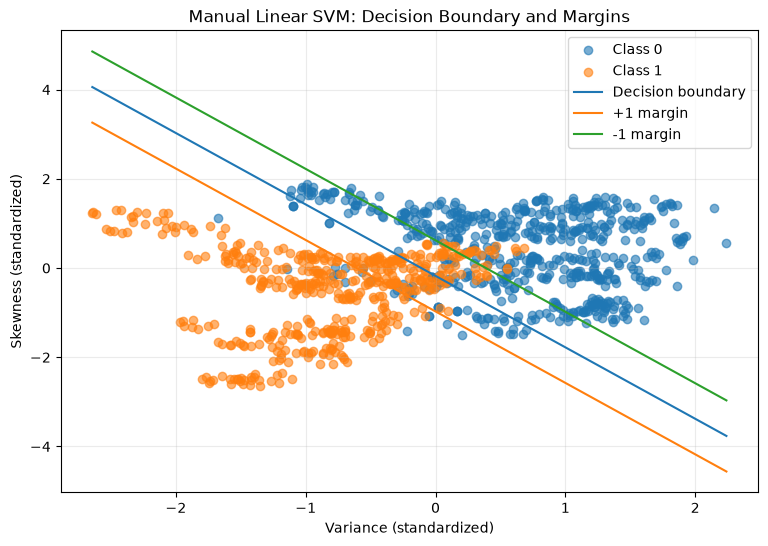

In [43]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 6))

# Plot training observations
plt.scatter(
    X_train_scaled[y_train_svm == -1, 0],
    X_train_scaled[y_train_svm == -1, 1],
    label="Class 0",
    alpha=0.6
)

plt.scatter(
    X_train_scaled[y_train_svm == 1, 0],
    X_train_scaled[y_train_svm == 1, 1],
    label="Class 1",
    alpha=0.6
)

# Generate x-coordinates for the boundary lines
x_values = np.linspace(
    X_train_scaled[:, 0].min(),
    X_train_scaled[:, 0].max(),
    300
)

# f(x) = w1*x1 + w2*x2 + b = level
# Therefore x2 = (level - b - w1*x1) / w2
for level, label in [(0, "Decision boundary"), (1, "+1 margin"), (-1, "-1 margin")]:
    y_values = (level - b - w[0] * x_values) / w[1]
    plt.plot(x_values, y_values, label=label)

plt.xlabel("Variance (standardized)")
plt.ylabel("Skewness (standardized)")
plt.title("Manual Linear SVM: Decision Boundary and Margins")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [44]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

sk_svm = SVC(kernel="linear", C=1.0)

sk_svm.fit(X_train_scaled, y_train_svm)

sk_train_pred = sk_svm.predict(X_train_scaled)
sk_test_pred = sk_svm.predict(X_test_scaled)

# Convert labels from -1/+1 back to 0/1
sk_test_pred_original = np.where(sk_test_pred == 1, 1, 0)

print("Scikit-learn Linear SVM — Test Results")
print("Accuracy :", accuracy_score(y_test, sk_test_pred_original))
print("Precision:", precision_score(y_test, sk_test_pred_original))
print("Recall   :", recall_score(y_test, sk_test_pred_original))
print("F1-score :", f1_score(y_test, sk_test_pred_original))

Scikit-learn Linear SVM — Test Results
Accuracy : 0.8763636363636363
Precision: 0.8492063492063492
Recall   : 0.8770491803278688
F1-score : 0.8629032258064516


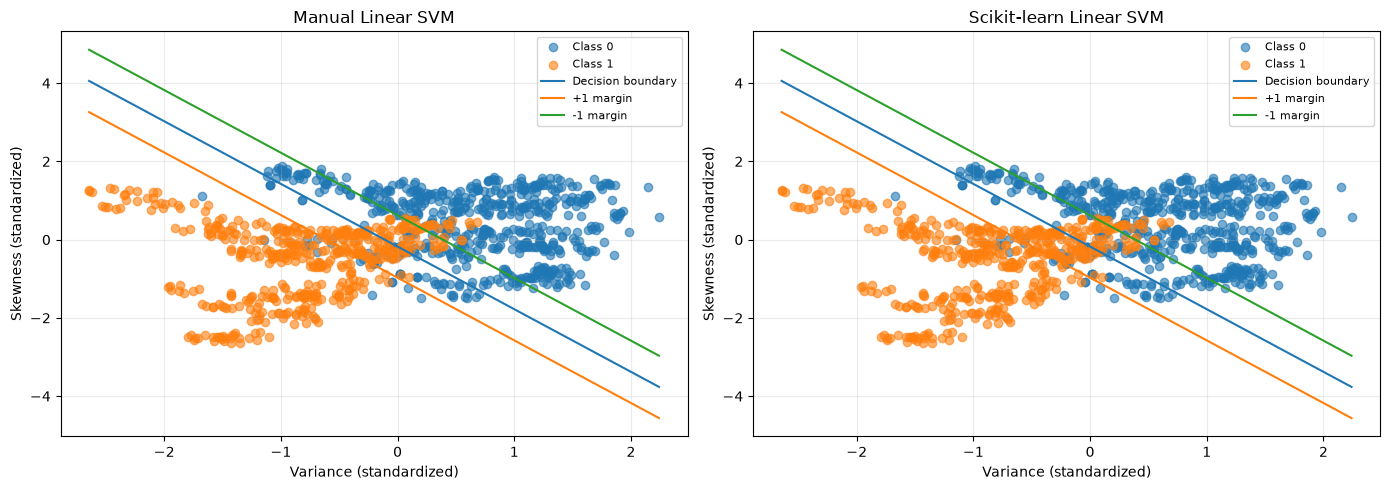

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = [
    (axes[0], w, b, "Manual Linear SVM"),
    (
        axes[1],
        sk_svm.coef_[0],
        sk_svm.intercept_[0],
        "Scikit-learn Linear SVM"
    )
]

for ax, weights, bias, title in models:
    ax.scatter(
        X_train_scaled[y_train_svm == -1, 0],
        X_train_scaled[y_train_svm == -1, 1],
        label="Class 0",
        alpha=0.6
    )
    ax.scatter(
        X_train_scaled[y_train_svm == 1, 0],
        X_train_scaled[y_train_svm == 1, 1],
        label="Class 1",
        alpha=0.6
    )

    x_values = np.linspace(
        X_train_scaled[:, 0].min(),
        X_train_scaled[:, 0].max(),
        300
    )

    for level, line_label in [
        (0, "Decision boundary"),
        (1, "+1 margin"),
        (-1, "-1 margin")
    ]:
        y_values = (
            level - bias - weights[0] * x_values
        ) / weights[1]
        ax.plot(x_values, y_values, label=line_label)

    ax.set_title(title)
    ax.set_xlabel("Variance (standardized)")
    ax.set_ylabel("Skewness (standardized)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [46]:
C_values = [0.01, 0.1, 1.0, 10.0]
results = []

for C_value in C_values:
    w_c, b_c, losses_c = train_svm(
        X_train_scaled,
        y_train_svm,
        C=C_value,
        learning_rate=0.0001,
        n_iterations=2000
    )

    train_pred_c = predict_svm(X_train_scaled, w_c, b_c)
    test_pred_c = predict_svm(X_test_scaled, w_c, b_c)

    results.append({
        "C": C_value,
        "Train Accuracy": np.mean(train_pred_c == y_train_svm),
        "Test Accuracy": np.mean(test_pred_c == y_test_svm),
        "Final Objective": losses_c[-1]
    })

import pandas as pd

results_df = pd.DataFrame(results)
print(results_df.round(4))

       C  Train Accuracy  Test Accuracy  Final Objective
0   0.01          0.8824         0.8836           4.5618
1   0.10          0.8833         0.8873          33.4051
2   1.00          0.8806         0.8764         311.9589
3  10.00          0.8806         0.8764        3093.9832


In [47]:
learning_rates = [0.00001, 0.00005, 0.0001, 0.0002]

lr_results = []

for lr in learning_rates:
    w_lr, b_lr, losses_lr = train_svm(
        X_train_scaled,
        y_train_svm,
        C=1.0,
        learning_rate=lr,
        n_iterations=2000
    )

    train_pred_lr = predict_svm(X_train_scaled, w_lr, b_lr)
    test_pred_lr = predict_svm(X_test_scaled, w_lr, b_lr)

    lr_results.append({
        "Learning Rate": lr,
        "Train Accuracy": np.mean(train_pred_lr == y_train_svm),
        "Test Accuracy": np.mean(test_pred_lr == y_test_svm),
        "Initial Objective": losses_lr[0],
        "Final Objective": losses_lr[-1]
    })

lr_results_df = pd.DataFrame(lr_results)
print(lr_results_df.round(4))

   Learning Rate  Train Accuracy  Test Accuracy  Initial Objective  \
0         0.0000          0.8833         0.8836          1088.3668   
1         0.0000          0.8797         0.8764          1053.8349   
2         0.0001          0.8806         0.8764          1010.6718   
3         0.0002          0.8806         0.8764           924.3522   

   Final Objective  
0         315.8776  
1         311.9735  
2         311.9589  
3         311.9590  


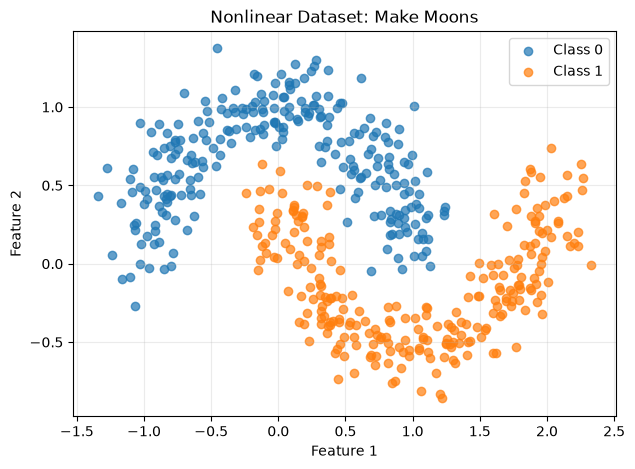

In [48]:
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
import numpy as np

X_moons, y_moons = make_moons(
    n_samples=500,
    noise=0.15,
    random_state=42
)

plt.figure(figsize=(7, 5))

plt.scatter(
    X_moons[y_moons == 0, 0],
    X_moons[y_moons == 0, 1],
    label="Class 0",
    alpha=0.7
)

plt.scatter(
    X_moons[y_moons == 1, 0],
    X_moons[y_moons == 1, 1],
    label="Class 1",
    alpha=0.7
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Nonlinear Dataset: Make Moons")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [49]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons,
    y_moons,
    test_size=0.2,
    random_state=42,
    stratify=y_moons
)

# Standardize using only the training data
moon_mean = X_moons_train.mean(axis=0)
moon_std = X_moons_train.std(axis=0)

X_moons_train_scaled = (X_moons_train - moon_mean) / moon_std
X_moons_test_scaled = (X_moons_test - moon_mean) / moon_std

models = {
    "Linear SVM": SVC(kernel="linear", C=1.0),
    "Polynomial SVM": SVC(kernel="poly", degree=3, C=1.0),
    "RBF SVM": SVC(kernel="rbf", C=1.0, gamma="scale")
}

kernel_results = []

for name, model in models.items():
    model.fit(X_moons_train_scaled, y_moons_train)
    predictions = model.predict(X_moons_test_scaled)

    kernel_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_moons_test, predictions),
        "Precision": precision_score(y_moons_test, predictions),
        "Recall": recall_score(y_moons_test, predictions),
        "F1-score": f1_score(y_moons_test, predictions)
    })

kernel_results_df = pd.DataFrame(kernel_results)
print(kernel_results_df.round(4))

            Model  Accuracy  Precision  Recall  F1-score
0      Linear SVM      0.87     0.8364    0.92    0.8762
1  Polynomial SVM      0.83     0.8235    0.84    0.8317
2         RBF SVM      0.99     1.0000    0.98    0.9899


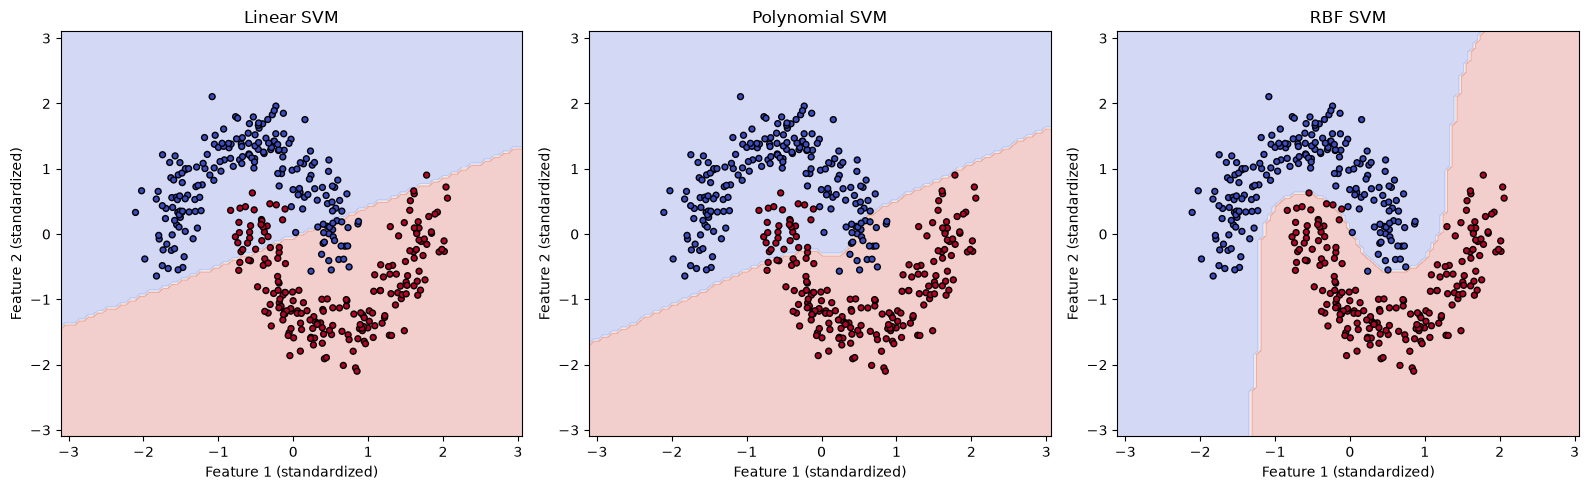

In [50]:
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, model) in zip(axes, models.items()):
    DecisionBoundaryDisplay.from_estimator(
        model,
        X_moons_train_scaled,
        response_method="predict",
        alpha=0.25,
        cmap=plt.cm.coolwarm,
        ax=ax
    )

    ax.scatter(
        X_moons_train_scaled[:, 0],
        X_moons_train_scaled[:, 1],
        c=y_moons_train,
        cmap=plt.cm.coolwarm,
        edgecolors="k",
        s=18
    )

    ax.set_title(name)
    ax.set_xlabel("Feature 1 (standardized)")
    ax.set_ylabel("Feature 2 (standardized)")

plt.tight_layout()
plt.show()

In [52]:
from sklearn.model_selection import train_test_split

# Use all four banknote features
feature_columns = ["variance", "skewness", "curtosis", "entropy"]

X_full = df[feature_columns].to_numpy()
y_full = df["class"].to_numpy()

# Same split settings used earlier
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full,
    y_full,
    test_size=0.2,
    random_state=42,
    stratify=y_full
)

print("X_train_full shape:", X_train_full.shape)
print("X_test_full shape:", X_test_full.shape)
print("y_train_full shape:", y_train_full.shape)
print("y_test_full shape:", y_test_full.shape)

X_train_full shape: (1097, 4)
X_test_full shape: (275, 4)
y_train_full shape: (1097,)
y_test_full shape: (275,)


In [53]:
# Standardize all four features for SVM models
X_mean_full = X_train_full.mean(axis=0)
X_std_full = X_train_full.std(axis=0)

X_train_full_scaled = (X_train_full - X_mean_full) / X_std_full
X_test_full_scaled = (X_test_full - X_mean_full) / X_std_full

# Convert labels to -1/+1 for the manual SVM
y_train_full_svm = np.where(y_train_full == 1, 1, -1)
y_test_full_svm = np.where(y_test_full == 1, 1, -1)

print("Training feature means after scaling:")
print(X_train_full_scaled.mean(axis=0).round(4))

print("\nTraining feature standard deviations:")
print(X_train_full_scaled.std(axis=0).round(4))

print("\nSVM labels:", np.unique(y_train_full_svm))

Training feature means after scaling:
[-0. -0. -0.  0.]

Training feature standard deviations:
[1. 1. 1. 1.]

SVM labels: [-1  1]


In [54]:
import time
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

start_time = time.perf_counter()

manual_tree_full = build_tree(
    X_train_full,
    y_train_full,
    max_depth=3,
    min_samples_split=2,
    criterion="gini"
)

manual_tree_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()

manual_tree_train_pred_full = predict_tree(
    manual_tree_full, X_train_full
)
manual_tree_test_pred_full = predict_tree(
    manual_tree_full, X_test_full
)

manual_tree_prediction_time = time.perf_counter() - start_time

print("Manual Decision Tree — Four Features")
print("Training accuracy:",
      accuracy_score(y_train_full, manual_tree_train_pred_full))
print("Testing accuracy:",
      accuracy_score(y_test_full, manual_tree_test_pred_full))
print("Training time:", round(manual_tree_train_time, 6), "seconds")
print("Prediction time (train + test):",
      round(manual_tree_prediction_time, 6), "seconds")

Manual Decision Tree — Four Features
Training accuracy: 0.9434822242479489
Testing accuracy: 0.9236363636363636
Training time: 0.577736 seconds
Prediction time (train + test): 0.001448 seconds


In [55]:
from sklearn.tree import DecisionTreeClassifier
import time

sk_tree_full = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

start_time = time.perf_counter()
sk_tree_full.fit(X_train_full, y_train_full)
sk_tree_full_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
sk_tree_train_pred_full = sk_tree_full.predict(X_train_full)
sk_tree_test_pred_full = sk_tree_full.predict(X_test_full)
sk_tree_full_prediction_time = time.perf_counter() - start_time

print("Scikit-learn Decision Tree — Four Features")
print("Training accuracy:",
      accuracy_score(y_train_full, sk_tree_train_pred_full))
print("Testing accuracy:",
      accuracy_score(y_test_full, sk_tree_test_pred_full))
print("Training time:", round(sk_tree_full_train_time, 6), "seconds")
print("Prediction time (train + test):",
      round(sk_tree_full_prediction_time, 6), "seconds")

Scikit-learn Decision Tree — Four Features
Training accuracy: 0.9434822242479489
Testing accuracy: 0.9236363636363636
Training time: 0.002968 seconds
Prediction time (train + test): 0.000878 seconds


In [56]:
import time

start_time = time.perf_counter()

w_full, b_full, losses_full = train_svm(
    X_train_full_scaled,
    y_train_full_svm,
    C=1.0,
    learning_rate=0.0001,
    n_iterations=2000
)

manual_svm_full_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()

manual_svm_train_pred_svm = predict_svm(
    X_train_full_scaled, w_full, b_full
)
manual_svm_test_pred_svm = predict_svm(
    X_test_full_scaled, w_full, b_full
)

manual_svm_full_prediction_time = time.perf_counter() - start_time

# Convert predictions from -1/+1 back to 0/1
manual_svm_train_pred_full = np.where(
    manual_svm_train_pred_svm == 1, 1, 0
)
manual_svm_test_pred_full = np.where(
    manual_svm_test_pred_svm == 1, 1, 0
)

print("Manual Linear SVM — Four Features")
print("Training accuracy:",
      accuracy_score(y_train_full, manual_svm_train_pred_full))
print("Testing accuracy:",
      accuracy_score(y_test_full, manual_svm_test_pred_full))
print("Training time:",
      round(manual_svm_full_train_time, 6), "seconds")
print("Prediction time (train + test):",
      round(manual_svm_full_prediction_time, 6), "seconds")
print("Final objective:", round(losses_full[-1], 4))

Manual Linear SVM — Four Features
Training accuracy: 0.9872379216043756
Testing accuracy: 0.9745454545454545
Training time: 0.092532 seconds
Prediction time (train + test): 0.0001 seconds
Final objective: 47.6337


In [57]:
from sklearn.svm import SVC
import time

sk_svm_full = SVC(kernel="linear", C=1.0)

start_time = time.perf_counter()
sk_svm_full.fit(X_train_full_scaled, y_train_full_svm)
sk_svm_full_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
sk_svm_train_pred_full_svm = sk_svm_full.predict(X_train_full_scaled)
sk_svm_test_pred_full_svm = sk_svm_full.predict(X_test_full_scaled)
sk_svm_full_prediction_time = time.perf_counter() - start_time

# Convert predictions back to original labels
sk_svm_train_pred_full = np.where(
    sk_svm_train_pred_full_svm == 1, 1, 0
)
sk_svm_test_pred_full = np.where(
    sk_svm_test_pred_full_svm == 1, 1, 0
)

print("Scikit-learn Linear SVM — Four Features")
print("Training accuracy:",
      accuracy_score(y_train_full, sk_svm_train_pred_full))
print("Testing accuracy:",
      accuracy_score(y_test_full, sk_svm_test_pred_full))
print("Training time:",
      round(sk_svm_full_train_time, 6), "seconds")
print("Prediction time (train + test):",
      round(sk_svm_full_prediction_time, 6), "seconds")

Scikit-learn Linear SVM — Four Features
Training accuracy: 0.9863263445761167
Testing accuracy: 0.9745454545454545
Training time: 0.006988 seconds
Prediction time (train + test): 0.001849 seconds


In [58]:
from sklearn.svm import SVC
import time

rbf_svm_full = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

start_time = time.perf_counter()
rbf_svm_full.fit(X_train_full_scaled, y_train_full)
rbf_svm_full_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
rbf_svm_train_pred_full = rbf_svm_full.predict(X_train_full_scaled)
rbf_svm_test_pred_full = rbf_svm_full.predict(X_test_full_scaled)
rbf_svm_full_prediction_time = time.perf_counter() - start_time

print("RBF SVM — Four Features")
print("Training accuracy:",
      accuracy_score(y_train_full, rbf_svm_train_pred_full))
print("Testing accuracy:",
      accuracy_score(y_test_full, rbf_svm_test_pred_full))
print("Training time:",
      round(rbf_svm_full_train_time, 6), "seconds")
print("Prediction time (train + test):",
      round(rbf_svm_full_prediction_time, 6), "seconds")

RBF SVM — Four Features
Training accuracy: 1.0
Testing accuracy: 1.0
Training time: 0.004619 seconds
Prediction time (train + test): 0.006851 seconds


In [60]:
import time
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Measure prediction time for the existing models.
# These measurements include predictions on both training and test sets.
prediction_functions = {
    "Manual Decision Tree": lambda: (
        predict_tree(manual_tree_full, X_train_full),
        predict_tree(manual_tree_full, X_test_full)
    ),
    "Scikit-learn Decision Tree": lambda: (
        sk_tree_full.predict(X_train_full),
        sk_tree_full.predict(X_test_full)
    ),
    "Manual Linear SVM": lambda: (
        np.where(predict_svm(X_train_full_scaled, w_full, b_full) == 1, 1, 0),
        np.where(predict_svm(X_test_full_scaled, w_full, b_full) == 1, 1, 0)
    ),
    "Scikit-learn Linear SVM": lambda: (
        np.where(sk_svm_full.predict(X_train_full_scaled) == 1, 1, 0),
        np.where(sk_svm_full.predict(X_test_full_scaled) == 1, 1, 0)
    ),
    "RBF SVM": lambda: (
        rbf_svm_full.predict(X_train_full_scaled),
        rbf_svm_full.predict(X_test_full_scaled)
    )
}

predictions = {}
prediction_times = {}

for name, predict_func in prediction_functions.items():
    start = time.perf_counter()
    train_pred, test_pred = predict_func()
    prediction_times[name] = time.perf_counter() - start
    predictions[name] = (train_pred, test_pred)

# Reuse the training times recorded from your earlier outputs.
training_times = {
    "Manual Decision Tree": 0.577736,
    "Scikit-learn Decision Tree": 0.002968,
    "Manual Linear SVM": 0.092532,
    "Scikit-learn Linear SVM": sk_svm_full_train_time,
    "RBF SVM": rbf_svm_full_train_time
}

rows = []

for name, (train_pred, test_pred) in predictions.items():
    rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train_full, train_pred),
        "Test Accuracy": accuracy_score(y_test_full, test_pred),
        "Precision": precision_score(y_test_full, test_pred, zero_division=0),
        "Recall": recall_score(y_test_full, test_pred, zero_division=0),
        "F1-Score": f1_score(y_test_full, test_pred, zero_division=0),
        "Training Time (s)": training_times[name],
        "Prediction Time (train + test) (s)": prediction_times[name]
    })

comparison_df = pd.DataFrame(rows)
display(comparison_df.round(4))

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score,Training Time (s),Prediction Time (train + test) (s)
0,Manual Decision Tree,0.9435,0.9236,0.8797,0.959,0.9176,0.5777,0.0012
1,Scikit-learn Decision Tree,0.9435,0.9236,0.8797,0.959,0.9176,0.0030,0.0006
2,Manual Linear SVM,0.9872,0.9745,0.9457,1.000,0.9721,0.0925,0.0001
3,Scikit-learn Linear SVM,0.9863,0.9745,0.9457,1.000,0.9721,0.0070,0.0014
4,RBF SVM,1.0000,1.0000,1.0000,1.000,1.0000,0.0046,0.0066


In [61]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

for C in [0.1, 1, 10, 100]:
    model = SVC(kernel="rbf", C=C, gamma="scale")
    model.fit(X_train_full_scaled, y_train_full)

    train_acc = accuracy_score(
        y_train_full, model.predict(X_train_full_scaled)
    )
    test_acc = accuracy_score(
        y_test_full, model.predict(X_test_full_scaled)
    )

    print(
        f"C={C:<5} | Train Accuracy={train_acc:.4f} "
        f"| Test Accuracy={test_acc:.4f}"
    )

C=0.1   | Train Accuracy=0.9918 | Test Accuracy=0.9855
C=1     | Train Accuracy=1.0000 | Test Accuracy=1.0000
C=10    | Train Accuracy=1.0000 | Test Accuracy=1.0000
C=100   | Train Accuracy=1.0000 | Test Accuracy=1.0000


In [62]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X_full = df[["variance", "skewness", "curtosis", "entropy"]].to_numpy()
y_full = df["class"].to_numpy()

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for C in [0.1, 1, 10, 100]:
    model = make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=C, gamma="scale")
    )

    scores = cross_validate(
        model,
        X_full,
        y_full,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        },
        return_train_score=True
    )

    results.append({
        "C": C,
        "Mean Train Accuracy": scores["train_accuracy"].mean(),
        "Mean CV Accuracy": scores["test_accuracy"].mean(),
        "CV Accuracy Std": scores["test_accuracy"].std(),
        "Mean CV Precision": scores["test_precision"].mean(),
        "Mean CV Recall": scores["test_recall"].mean(),
        "Mean CV F1": scores["test_f1"].mean()
    })

cv_results = pd.DataFrame(results)
display(cv_results.round(4))

,C,Mean Train Accuracy,Mean CV Accuracy,CV Accuracy Std,Mean CV Precision,Mean CV Recall,Mean CV F1
0,0.1,0.9905,0.9905,0.0049,0.9792,1.0,0.9895
1,1.0,1.0000,1.0000,0.0000,1.0000,1.0,1.0000
2,10.0,1.0000,1.0000,0.0000,1.0000,1.0,1.0000
3,100.0,1.0000,1.0000,0.0000,1.0000,1.0,1.0000


In [63]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Use all four features
X_cv = df[["variance", "skewness", "curtosis", "entropy"]].to_numpy()
y_cv = df["class"].to_numpy()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model_names = [
    "Manual Decision Tree",
    "Scikit-learn Decision Tree",
    "Manual Linear SVM",
    "Scikit-learn Linear SVM",
    "RBF SVM"
]

fold_results = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_cv, y_cv), start=1):
    X_train, X_val = X_cv[train_idx], X_cv[val_idx]
    y_train, y_val = y_cv[train_idx], y_cv[val_idx]

    # Standardize using only the current training fold
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)

    # Convert labels to -1/+1 for the manual SVM
    y_train_svm = np.where(y_train == 1, 1, -1)

    # 1. Manual Decision Tree
    manual_tree = build_tree(
        X_train, y_train, max_depth=3,
        min_samples_split=2, criterion="gini"
    )
    manual_tree_train = predict_tree(manual_tree, X_train)
    manual_tree_val = predict_tree(manual_tree, X_val)

    # 2. Scikit-learn Decision Tree
    sklearn_tree = DecisionTreeClassifier(
        criterion="gini", max_depth=3, random_state=42
    )
    sklearn_tree.fit(X_train, y_train)
    sklearn_tree_train = sklearn_tree.predict(X_train)
    sklearn_tree_val = sklearn_tree.predict(X_val)

    # 3. Manual Linear SVM
    w, b, _ = train_svm(
        X_train_scaled, y_train_svm,
        C=1.0, learning_rate=0.0001, n_iterations=2000
    )
    manual_svm_train = np.where(
        predict_svm(X_train_scaled, w, b) == 1, 1, 0
    )
    manual_svm_val = np.where(
        predict_svm(X_val_scaled, w, b) == 1, 1, 0
    )

    # 4. Scikit-learn Linear SVM
    sklearn_linear = SVC(kernel="linear", C=1.0)
    sklearn_linear.fit(X_train_scaled, y_train)
    sklearn_linear_train = sklearn_linear.predict(X_train_scaled)
    sklearn_linear_val = sklearn_linear.predict(X_val_scaled)

    # 5. RBF SVM
    rbf = SVC(kernel="rbf", C=1.0, gamma="scale")
    rbf.fit(X_train_scaled, y_train)
    rbf_train = rbf.predict(X_train_scaled)
    rbf_val = rbf.predict(X_val_scaled)

    predictions = {
        "Manual Decision Tree": (manual_tree_train, manual_tree_val),
        "Scikit-learn Decision Tree": (sklearn_tree_train, sklearn_tree_val),
        "Manual Linear SVM": (manual_svm_train, manual_svm_val),
        "Scikit-learn Linear SVM": (sklearn_linear_train, sklearn_linear_val),
        "RBF SVM": (rbf_train, rbf_val)
    }

    for name, (train_pred, val_pred) in predictions.items():
        fold_results.append({
            "Fold": fold,
            "Model": name,
            "Train Accuracy": accuracy_score(y_train, train_pred),
            "CV Accuracy": accuracy_score(y_val, val_pred),
            "CV Precision": precision_score(
                y_val, val_pred, zero_division=0
            ),
            "CV Recall": recall_score(
                y_val, val_pred, zero_division=0
            ),
            "CV F1": f1_score(
                y_val, val_pred, zero_division=0
            )
        })

# Results for every fold
fold_results_df = pd.DataFrame(fold_results)

# Summary across the five folds
summary = fold_results_df.groupby("Model").agg(
    Mean_Train_Accuracy=("Train Accuracy", "mean"),
    Mean_CV_Accuracy=("CV Accuracy", "mean"),
    CV_Accuracy_Std=("CV Accuracy", "std"),
    Mean_CV_Precision=("CV Precision", "mean"),
    Mean_CV_Recall=("CV Recall", "mean"),
    Mean_CV_F1=("CV F1", "mean")
).reset_index()

display(summary.round(4))

,Model,Mean_Train_Accuracy,Mean_CV_Accuracy,CV_Accuracy_Std,Mean_CV_Precision,Mean_CV_Recall,Mean_CV_F1
0,Manual Decision Tree,0.9410,0.9366,0.0085,0.9365,0.9197,0.9280
1,Manual Linear SVM,0.9845,0.9847,0.0091,0.9685,0.9984,0.9831
2,RBF SVM,1.0000,1.0000,0.0000,1.0000,1.0000,1.0000
3,Scikit-learn Decision Tree,0.9410,0.9366,0.0085,0.9365,0.9197,0.9280
4,Scikit-learn Linear SVM,0.9843,0.9840,0.0076,0.9685,0.9967,0.9823
